# 02 — Data Preprocessing
**Project:** California Property Close Price Prediction (IDX Exchange, team ds76)
**Week 3 deliverable:** handle missing values, encode categoricals, scale numerics, and build a time-based train/test split with a tuned training window (X months).

Same scope as Week 2: `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"`, target **`ClosePrice`**.

All of the code lives in **`preprocessing.py`** so Weeks 4–8 can reuse the same steps with one import. It does two kinds of work:
* **`clean()`**: fixed rules (filters, dedupe, impossible values set to NaN). Safe to run on every month at once.
* **`build_preprocessor()`**: learned steps (imputation, encoding, scaling). It is **fit on the training window only**, so the test month never leaks into training.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # newer sklearn deprecation notices

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

from preprocessing import *   # load_raw, clean, time_split, build_preprocessor, price_model, column lists

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load all months and clean
Week 2 used Oct 2025 – May 2026. The folder now holds **Jan 2024 – May 2026**.

In [2]:
raw = load_raw(".")
print(f"{raw['SourceMonth'].nunique()} files, {len(raw):,} rows, {raw.shape[1]} columns\n")
df = clean(raw)
print(f"\nClean dataset: {df.shape[0]:,} sales x {df.shape[1]} columns")
df.groupby(df["CloseDate"].dt.to_period("M")).size().rename("sales").to_frame().T

27 files, 591,028 rows, 83 columns

SFR filter                        297,596
dedupe ListingKey                 297,341
drop bad price / living area      296,795

Clean dataset: 296,795 sales x 32 columns


CloseDate,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05
sales,8310,9543,11618,12710,13779,12518,13334,12382,10877,12325,10658,10593,8124,8829,10590,11845,11727,11667,12088,11998,9705,10430,7462,8527,11156,12000,12000


### Cleaning rules (in `clean()`)
| Rule | Why |
|---|---|
| Keep Residential + SingleFamilyResidence | Task scope |
| Dedupe on `ListingKey`, keep the latest file's record | 255 listings appear in two monthly files |
| Drop rows with ClosePrice outside \$50K–\$30M, LivingArea outside 300–20,000 sq ft, or \$/sq ft outside \$25–\$5,000 | Week 2 found clear entry errors (\$1.75 sales, a \$989.5M sale). These only remove about 0.2% of rows |
| Bedrooms or baths outside 1–15, YearBuilt before 1850 or in the future, lot ≤ 0, garage > 20, parking < 0 or > 50, main-level beds > total beds → **NaN** | Impossible values. We blank them and let the imputer fill them instead of throwing away the whole sale |
| Coordinates outside California → NaN, then fill missing coordinates with the median of the same ZIP | 42 rows were outside CA in Week 2. A ZIP median uses no price info, so it can't leak |
| `AssociationFee` converted to a monthly amount (`AssociationFeeMonthly`). No fee listed → 0 | Week 2 note: fees come in Monthly, Quarterly, SemiAnnually, or Annually units |
| `Levels` "One,Two" → first value; `Flooring` split into 6 yes/no columns (Tile, Carpet, Wood, Laminate, Vinyl, Stone) | Turns messy text into usable features |

## 2. Columns dropped and why
| Group | Columns | Reason |
|---|---|---|
| **Leakage** | ListPrice, OriginalListPrice, DaysOnMarket, ListingContractDate, PurchaseContractDate, ContractStatusChangeDate | Only known once a home is listed or sold. The task asks for a price for *any* home, including ones not for sale. ListPrice has ρ = 0.99 with ClosePrice (Week 2) |
| IDs & addresses | ListingKey*, ListingId, UnparsedAddress, StreetNumberNumeric | Not property characteristics (ListingKey and CloseDate are kept only for bookkeeping and the split) |
| Agents & offices | ListAgent\*, CoListAgent\*, BuyerAgent\*, \*OfficeName, \*AOR, BuyerAgencyCompensation\* | Describe who handled the sale, not the home |
| Empty or near-empty (>90% missing) | TaxYear, TaxAnnualAmount, BusinessType, CoveredSpaces, FireplacesTotal, Above/BelowGradeFinishedArea, Elementary/MiddleSchoolDistrict, WaterfrontYN, BasementYN, BuilderName, LotSizeDimensions, BuildingAreaTotal | Too little data to use |
| Redundant | LotSizeAcres, LotSizeArea | Same information as LotSizeSquareFeet |
| Too sparse or too many levels | School names (>80% missing), SubdivisionName (65% missing, 11K levels), StateOrProvince | Week 6 will add a school-district layer from the shapefile instead |
| Constant | PropertyType, PropertySubType, MlsStatus | One value after filtering |

In [3]:
print(f"{len(FEATURES)} features kept:")
for name, cols in [("skewed numeric (log1p)", SKEWED), ("numeric", NUMERIC), ("yes/no", BINARY),
                   ("one-hot", LOW_CARD), ("target-encoded", HIGH_CARD), ("flooring", FLOORING_COLS)]:
    print(f"  {name:<24}{cols}")

29 features kept:
  skewed numeric (log1p)  ['LivingArea', 'LotSizeSquareFeet', 'AssociationFeeMonthly']
  numeric                 ['BedroomsTotal', 'BathroomsTotalInteger', 'YearBuilt', 'GarageSpaces', 'ParkingTotal', 'Stories', 'MainLevelBedrooms', 'Latitude', 'Longitude']
  yes/no                  ['ViewYN', 'PoolPrivateYN', 'FireplaceYN', 'AttachedGarageYN', 'NewConstructionYN']
  one-hot                 ['CountyOrParish', 'Levels']
  target-encoded          ['City', 'PostalCode', 'MLSAreaMajor', 'HighSchoolDistrict']
  flooring                ['Floor_Tile', 'Floor_Carpet', 'Floor_Wood', 'Floor_Laminate', 'Floor_Vinyl', 'Floor_Stone']


## 3. Missing values: drop, impute, or flag?

In [4]:
miss = (df[FEATURES].isna().mean() * 100).round(1)
miss = miss[miss > 0].sort_values(ascending=False).to_frame("% missing")
decision = {c: "median impute + missing flag" for c in SKEWED + NUMERIC}
decision.update({c: "fill 0 (= not listed) + missing flag" for c in BINARY})
miss["decision"] = miss.index.map(decision)
miss

,% missing,decision
MainLevelBedrooms,41.000,median impute + missing flag
Stories,12.900,median impute + missing flag
AttachedGarageYN,11.500,fill 0 (= not listed) + missing flag
PoolPrivateYN,9.700,fill 0 (= not listed) + missing flag
ViewYN,8.900,fill 0 (= not listed) + missing flag
NewConstructionYN,7.200,fill 0 (= not listed) + missing flag
GarageSpaces,3.600,median impute + missing flag
LotSizeSquareFeet,1.800,median impute + missing flag
ParkingTotal,0.200,median impute + missing flag
YearBuilt,0.100,median impute + missing flag


**Decisions**
* **No more rows are dropped for missing values.** After cleaning, the target, LivingArea, beds, baths, and location are almost fully populated.
* **Numeric columns → median, plus a 0/1 "was missing" flag** (`SimpleImputer(add_indicator=True)`). The median is robust to the outliers we saw in Week 2. The flag lets a model learn whether "missing" itself means something. For example, MainLevelBedrooms is 41% missing, which is too much to drop but too useful to ignore.
* **Yes/no columns → 0 plus a flag.** A blank pool or view field usually means the agent didn't tick it.
* **Categorical columns → their own "Missing" level.**
* Every imputer value (each median) is learned **from the training window only**.

## 4. Encoding and scaling
| Column type | Transform |
|---|---|
| Skewed size columns (LivingArea, LotSize, HOA) | `log1p` → median impute → standardize. Lot size goes up to 2 billion sq ft, so a log scale is needed before scaling |
| Other numeric columns | median impute → standardize (mean 0, sd 1) |
| Yes/no columns | 0/1 |
| CountyOrParish (63 levels), Levels | **one-hot**. Levels with fewer than 50 training sales are grouped as "infrequent" |
| City (1.1K), PostalCode (3.1K), MLSAreaMajor (1K), HighSchoolDistrict (440) | **target encoding**: each level becomes its average log price, cross-fitted so a row never sees its own price. One-hot would create about 5,000 sparse columns |

Scaling matters for Linear Regression (Week 4). Tree models (Weeks 5 and 7) don't care, but scaling doesn't hurt them.

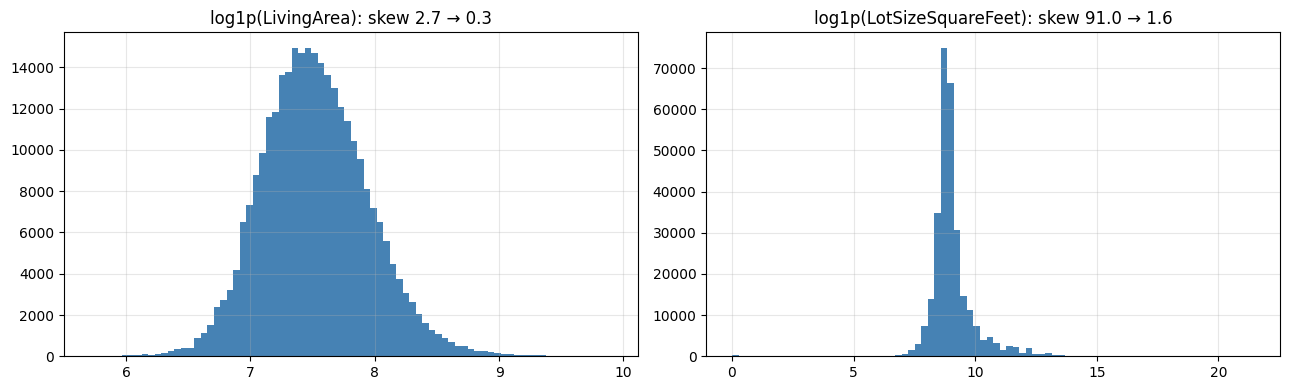

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, ["LivingArea", "LotSizeSquareFeet"]):
    s = df[c].dropna()
    ax.hist(np.log1p(s), bins=80, color="steelblue")
    ax.set_title(f"log1p({c}): skew {s.skew():.1f} → {np.log1p(s).skew():.1f}")
plt.tight_layout(); plt.show()

In [6]:
# Fit on one example window and inspect the model-ready matrix
train, test = time_split(df, "2026-05", 6)
prep = build_preprocessor().set_output(transform="pandas")
Xtr = prep.fit_transform(train[FEATURES], np.log(train[TARGET]))
Xte = prep.transform(test[FEATURES])

assert not Xtr.isna().any().any() and not Xte.isna().any().any(), "NaN left after preprocessing"
assert list(Xtr.columns) == list(Xte.columns)
print(f"train {Xtr.shape}, test {Xte.shape}: no missing values")
Xtr.describe().T[["mean", "std", "min", "max"]].head(15)

train (59280, 80), test (12000, 80): no missing values


,mean,std,min,max
LivingArea,-0.000,1.000,-4.117,5.184
LotSizeSquareFeet,0.000,1.000,-8.706,11.857
AssociationFeeMonthly,0.000,1.000,-0.581,3.199
missingindicator_LotSizeSquareFeet,0.000,1.000,-0.135,7.415
BedroomsTotal,-0.000,1.000,-2.599,11.989
BathroomsTotalInteger,0.000,1.000,-1.461,10.156
YearBuilt,0.000,1.000,-4.415,1.796
GarageSpaces,0.000,1.000,-2.212,20.163
ParkingTotal,0.000,1.000,-1.270,21.824
Stories,-0.000,1.000,-0.677,1.477


## 5. Train/test split: most recent month = test
* **Test set:** May 2026, the latest month we have.
* **Training set:** the **X** calendar months immediately before it.

Split by time, not randomly. The model will be used to price homes *in the future*, so it should be tested the same way. A random split would let it learn from sales that happened after the ones it is tested on.

### Choosing X without peeking at the test set
If we picked X by test R², the test score would no longer be an honest estimate. So:
1. **Validation:** treat **April 2026** as a stand-in test month and train on the X months before it. Pick X here.
2. **Test:** with that X, train on the X months before **May 2026** and report the test R² once.

We use two quick probe models: Linear Regression (next week's baseline) and a gradient-boosted tree. Both train on log(price) and predict in dollars. R² is measured in dollars.

In [7]:
WINDOWS = [1, 2, 3, 4, 6, 9, 12, 18, 24]
PROBES = {"LinearRegression": LinearRegression,
          "HistGradientBoosting": lambda: HistGradientBoostingRegressor(random_state=0)}

def r2_for_window(target_month, X, make_model):
    tr, te = time_split(df, target_month, X)
    assert tr["CloseDate"].max() < te["CloseDate"].min()       # no future data in training
    model = price_model(make_model()).fit(tr[FEATURES], tr[TARGET])
    return r2_score(te[TARGET], model.predict(te[FEATURES])), len(tr)

rows = []
for X in WINDOWS:
    for name, make in PROBES.items():
        r2, n = r2_for_window("2026-04", X, make)
        rows.append({"X_months": X, "model": name, "train_rows": n, "val_R2": r2})
sweep = pd.DataFrame(rows)
sweep.pivot(index="X_months", columns="model", values="val_R2").assign(
    train_rows=sweep.groupby("X_months")["train_rows"].first())

model,HistGradientBoosting,LinearRegression,train_rows
X_months,,,
1,0.825,0.784,11156
2,0.835,0.784,19683
3,0.843,0.787,27145
4,0.846,0.784,37575
6,0.846,0.783,59278
9,0.847,0.785,71366
12,0.847,0.787,106605
18,0.850,0.785,167724
24,0.845,0.782,243324


In [8]:
val = sweep.pivot(index="X_months", columns="model", values="val_R2")
val["mean"] = val.mean(axis=1)
best = val["mean"].max()
# Prefer the shortest window within 0.002 of the best: fresher prices and faster training
BEST_X = int(val.index[val["mean"] >= best - 0.002].min())

print(f"Chosen training window: X = {BEST_X} months")

Chosen training window: X = 9 months


**Reading the results:**
* **1–2 months is too little.** With so few sales, the city and ZIP averages are noisy. The tree model loses about 0.02 R².
* **After about 3–4 months the curve is flat.** Going from 4 to 24 months (6x the rows, and stale 2024 prices) adds at most +0.002 R² for the tree model and nothing for Linear Regression. Windows longer than 6 months also include the missing Aug–Sep 2025 gap.
* So we pick the **shortest window that is effectively as good as the best one: X = 4 months** (Jan–Apr 2026 when testing on May 2026). It is fresher, faster to train, and simpler to explain. Re-run this sweep when new months are added. Week 6 features, such as a sale-date trend, could make longer windows more useful.

In [9]:
test_rows = []
for name, make in PROBES.items():
    r2, n = r2_for_window("2026-05", BEST_X, make)
    test_rows.append({"model": name, "X_months": BEST_X, "train_rows": n, "test_R2 (May 2026)": r2})
pd.DataFrame(test_rows)

,model,X_months,train_rows,test_R2 (May 2026)
0,LinearRegression,9,71278,0.801
1,HistGradientBoosting,9,71278,0.856


These are **preview** scores only, to sanity-check the pipeline. The proper baseline is Week 4, and the model comparison is Weeks 5 and 7.

## 6. Save the cleaned CSV

In [10]:
train, test = time_split(df, "2026-05", BEST_X)
out = df.copy()
out["Split"] = "unused"
out.loc[train.index, "Split"] = "train"
out.loc[test.index, "Split"] = "test"
out.to_csv("cleaned_sfr.csv", index=False)
print(f"cleaned_sfr.csv: {len(out):,} rows x {out.shape[1]} cols")
out["Split"].value_counts().to_frame("rows")

cleaned_sfr.csv: 296,795 rows x 33 cols


,rows
Split,
unused,213517
train,71278
test,12000


`cleaned_sfr.csv` holds the **cleaned but not yet imputed or encoded** rows. Imputation and encoding have to be refit on whichever training window a later notebook uses. The `Split` column marks the chosen-X train/test rows. To get model-ready data in Week 4:
```python
from preprocessing import *
df = pd.read_csv("cleaned_sfr.csv", parse_dates=["CloseDate"], dtype={"PostalCode": str})
train, test = df[df.Split == "train"], df[df.Split == "test"]
model = price_model(LinearRegression()).fit(train[FEATURES], train[TARGET])
```

## Summary
* Cleaning removed 801 rows (dedupe + clear errors) out of 297.6K single-family sales. Impossible values were blanked, not dropped.
* Missing values: median or 0 fill **plus a missing flag**, learned on the training window only.
* Encoding: one-hot for county and levels; cross-fitted target encoding for City, ZIP, MLS area, and high-school district.
* Scaling: log1p on skewed sizes, then standardization.
* Split: test = May 2026. The training window was tuned on April 2026 validation → **X = 4 months** (Jan–Apr 2026, 39K sales).
* Preview test R² (May 2026): Linear Regression ≈ 0.80, gradient boosting ≈ 0.85, without ListPrice.
* Open question for the team: we excluded ListPrice as leakage. Adding it would raise R² a lot, but the model could then only price homes that are already listed.